In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv('retail_store_inventory.csv')

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(

In [ ]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


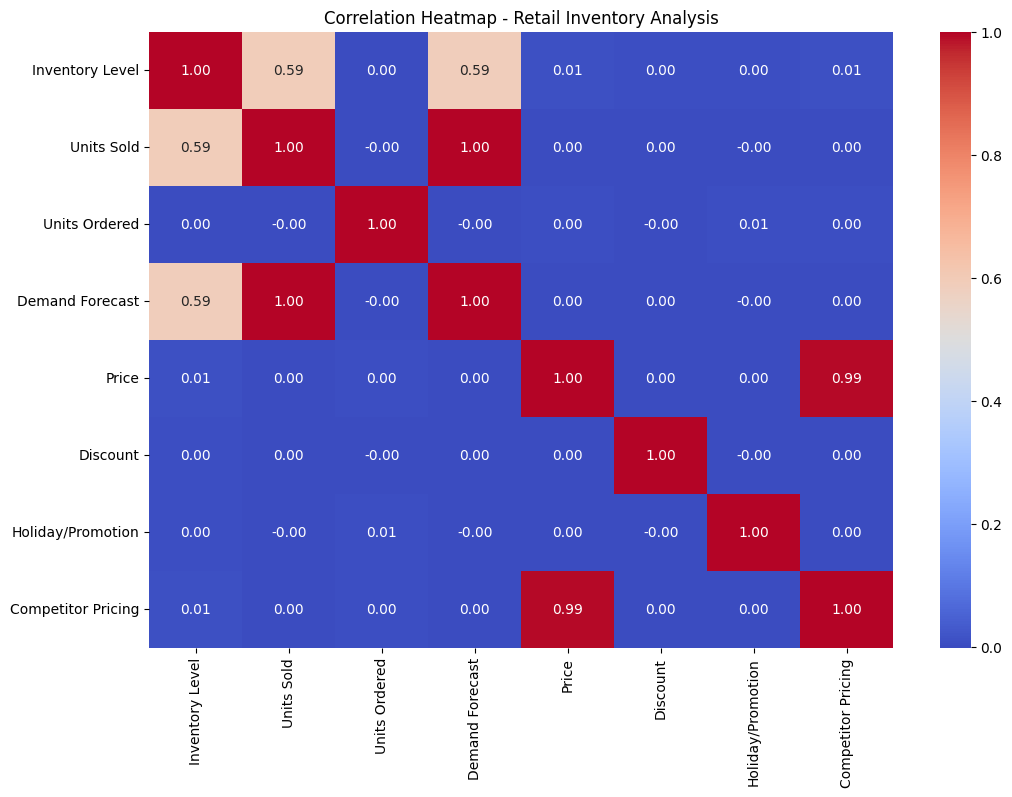

In [ ]:
correlation = df.select_dtypes(include='number').corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap - Retail Inventory Analysis')
plt.show()

In [ ]:
correlation.round(2)

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
Inventory Level,1.00,0.59,0.00,0.59,0.01,0.0,0.00,0.01
Units Sold,0.59,1.00,-0.00,1.00,0.00,0.0,-0.00,0.00
Units Ordered,0.00,-0.00,1.00,-0.00,0.00,-0.0,0.01,0.00
Demand Forecast,0.59,1.00,-0.00,1.00,0.00,0.0,-0.00,0.00
Price,0.01,0.00,0.00,0.00,1.00,0.0,0.00,0.99
Discount,0.00,0.00,-0.00,0.00,0.00,1.0,-0.00,0.00
Holiday/Promotion,0.00,-0.00,0.01,-0.00,0.00,-0.0,1.00,0.00
Competitor Pricing,0.01,0.00,0.00,0.00,0.99,0.0,0.00,1.00


In [ ]:
# Calculate revenue before discount
df['revenue'] = df['units_sold'] * df['price']

# Calculate net revenue after discount
df['net_revenue'] = (
    df['units_sold'] * df['price'] *
    (1 - df['discount_pct'] / 100)
)

# Assume cost is 70% of selling price
df['estimated_cost'] = df['units_sold'] * df['price'] * 0.70

# Calculate estimated gross profit
df['estimated_gross_profit'] = (
    df['net_revenue'] - df['estimated_cost']
)

print("New columns created successfully!")

df[['category', 'units_sold', 'net_revenue',
    'estimated_gross_profit']].head()

KeyError: 'units_sold'

In [ ]:
print(df.columns.tolist())

['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']


In [ ]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r'[^a-z0-9]+', '_', regex=True)
    .str.strip('_')
)

print(df.columns.tolist())

['date', 'store_id', 'product_id', 'category', 'region', 'inventory_level', 'units_sold', 'units_ordered', 'demand_forecast', 'price', 'discount', 'weather_condition', 'holiday_promotion', 'competitor_pricing', 'seasonality']


In [ ]:
df['revenue'] = df['units_sold'] * df['price']

df['net_revenue'] = (
    df['revenue'] * (1 - df['discount'] / 100)
)

df['estimated_cost'] = df['revenue'] * 0.70

df['estimated_gross_profit'] = (
    df['net_revenue'] - df['estimated_cost']
)

print("Revenue and estimated profit columns created successfully!")

df[['category', 'units_sold', 'net_revenue',
    'estimated_gross_profit']].head()

Revenue and estimated profit columns created successfully!


,category,units_sold,net_revenue,estimated_gross_profit
0,Groceries,127,3403.600,425.450
1,Toys,150,7561.200,945.150
2,Toys,65,1637.415,363.870
3,Toys,61,1796.328,399.184
4,Electronics,14,1030.960,309.288


In [ ]:
category_analysis = df.groupby('category').agg(
    total_units_sold=('units_sold', 'sum'),
    total_revenue=('revenue', 'sum'),
    net_revenue=('net_revenue', 'sum'),
    estimated_gross_profit=('estimated_gross_profit', 'sum')
).reset_index()

category_analysis = category_analysis.sort_values(
    by='net_revenue', ascending=False
)

category_analysis.round(2)

,category,total_units_sold,total_revenue,net_revenue,estimated_gross_profit
2,Furniture,2025017,1.115118e+08,1.002308e+08,22172561.00
3,Groceries,2000482,1.109845e+08,9.994897e+07,22259791.58
4,Toys,1990485,1.096424e+08,9.872922e+07,21979505.73
0,Clothing,1999166,1.096510e+08,9.867678e+07,21921054.08
1,Electronics,1960432,1.084391e+08,9.738559e+07,21478243.11


In [ ]:
seasonal_analysis = df.groupby('seasonality').agg(
    total_units_sold=('units_sold', 'sum'),
    total_revenue=('revenue', 'sum'),
    net_revenue=('net_revenue', 'sum')
).reset_index()

seasonal_analysis = seasonal_analysis.sort_values(
    by='net_revenue', ascending=False
)

seasonal_analysis.round(2)

,seasonality,total_units_sold,total_revenue,net_revenue
3,Winter,2501951,1.382696e+08,1.243587e+08
0,Autumn,2506676,1.380592e+08,1.241495e+08
1,Spring,2487940,1.371123e+08,1.232956e+08
2,Summer,2479015,1.367878e+08,1.231676e+08


In [ ]:
df['date'] = pd.to_datetime(df['date'])

df['month'] = df['date'].dt.month_name()

monthly_analysis = df.groupby('month').agg(
    total_units_sold=('units_sold', 'sum'),
    net_revenue=('net_revenue', 'sum')
).reset_index()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_analysis['month'] = pd.Categorical(
    monthly_analysis['month'],
    categories=month_order,
    ordered=True
)

monthly_analysis = monthly_analysis.sort_values('month')

monthly_analysis.round(2)

,month,total_units_sold,net_revenue
4,January,856590,42271438.52
3,February,776220,38289979.90
7,March,842595,42467371.80
0,April,808457,40512380.95
8,May,833472,41269287.28
6,June,821150,41028075.63
5,July,864547,42600864.60
1,August,841417,41621851.94
11,September,816971,40505250.84
10,October,852509,42060412.54


In [ ]:
inventory_analysis = df.groupby('category').agg(
    total_inventory=('inventory_level', 'sum'),
    total_units_sold=('units_sold', 'sum'),
    average_inventory=('inventory_level', 'mean')
).reset_index()

inventory_analysis['inventory_turnover_proxy'] = (
    inventory_analysis['total_units_sold'] /
    inventory_analysis['total_inventory']
)

inventory_analysis.round(2)

,category,total_inventory,total_units_sold,average_inventory,inventory_turnover_proxy
0,Clothing,4016267,1999166,274.60,0.5
1,Electronics,3957182,1960432,272.51,0.5
2,Furniture,4054223,2025017,275.82,0.5
3,Groceries,4029065,2000482,275.76,0.5
4,Toys,4007011,1990485,273.65,0.5


In [ ]:
inventory_analysis = df.groupby('category').agg(
    total_inventory=('inventory_level', 'sum'),
    total_units_sold=('units_sold', 'sum'),
    average_inventory=('inventory_level', 'mean')
).reset_index()

inventory_analysis['inventory_turnover_proxy'] = (
    inventory_analysis['total_units_sold'] /
    inventory_analysis['total_inventory']
)

inventory_analysis.round(2)

,category,total_inventory,total_units_sold,average_inventory,inventory_turnover_proxy
0,Clothing,4016267,1999166,274.60,0.5
1,Electronics,3957182,1960432,272.51,0.5
2,Furniture,4054223,2025017,275.82,0.5
3,Groceries,4029065,2000482,275.76,0.5
4,Toys,4007011,1990485,273.65,0.5


In [ ]:
valid_df = df[df['demand_forecast'] >= 0].copy()

valid_df['inventory_status'] = np.where(
    valid_df['inventory_level'] > valid_df['demand_forecast'],
    'Excess Stock',
    np.where(
        valid_df['inventory_level'] < valid_df['demand_forecast'],
        'Stock Shortage Risk',
        'Balanced'
    )
)

risk_analysis = valid_df['inventory_status'].value_counts().reset_index()
risk_analysis.columns = ['inventory_status', 'record_count']

risk_analysis

,inventory_status,record_count
0,Excess Stock,69839
1,Stock Shortage Risk,2585
2,Balanced,3


In [ ]:
category_risk = valid_df.groupby(
    ['category', 'inventory_status']
).size().unstack(fill_value=0).reset_index()

category_risk

inventory_status,category,Balanced,Excess Stock,Stock Shortage Risk
0,Clothing,0,13984,510
1,Electronics,0,13884,508
2,Furniture,2,14044,524
3,Groceries,1,13932,535
4,Toys,0,13995,508


In [ ]:
store_analysis = df.groupby('store_id').agg(
    total_units_sold=('units_sold', 'sum'),
    net_revenue=('net_revenue', 'sum'),
    average_inventory=('inventory_level', 'mean')
).reset_index()

store_analysis.sort_values(
    by='net_revenue', ascending=False
).round(2)

,store_id,total_units_sold,net_revenue,average_inventory
4,S005,2010176,1.005036e+08,276.50
2,S003,2022696,1.000344e+08,276.87
1,S002,1987715,9.895000e+07,273.33
3,S004,1979245,9.805714e+07,272.30
0,S001,1975750,9.742619e+07,273.34


In [ ]:
df['year'] = df['date'].dt.year

year_analysis = df.groupby('year').agg(
    total_units_sold=('units_sold', 'sum'),
    net_revenue=('net_revenue', 'sum')
).reset_index()

year_analysis

,year,total_units_sold,net_revenue
0,2022,4991624,2.484549e+08
1,2023,4970714,2.458884e+08
2,2024,13244,6.281428e+05


In [ ]:
promotion_analysis = df.groupby('holiday_promotion').agg(
    total_units_sold=('units_sold', 'sum'),
    net_revenue=('net_revenue', 'sum'),
    average_units_sold=('units_sold', 'mean')
).reset_index()

promotion_analysis

,holiday_promotion,total_units_sold,net_revenue,average_units_sold
0,0,5016163,2.487493e+08,136.505375
1,1,4959419,2.462221e+08,136.423926


In [ ]:
weather_analysis = df.groupby('weather_condition').agg(
    total_units_sold=('units_sold', 'sum'),
    net_revenue=('net_revenue', 'sum')
).reset_index()

weather_analysis.sort_values(
    by='net_revenue', ascending=False
).round(2)

,weather_condition,total_units_sold,net_revenue
3,Sunny,2524544,1.251129e+08
0,Cloudy,2497207,1.246522e+08
1,Rainy,2470455,1.230322e+08
2,Snowy,2483376,1.221741e+08


In [ ]:
category_season_analysis = df.groupby(
    ['category', 'seasonality']
).agg(
    total_units_sold=('units_sold', 'sum'),
    net_revenue=('net_revenue', 'sum')
).reset_index()

category_season_analysis.sort_values(
    by=['category', 'net_revenue'],
    ascending=[True, False]
).round(2)

,category,seasonality,total_units_sold,net_revenue
3,Clothing,Winter,504972,25108750.60
0,Clothing,Autumn,498364,24642234.04
1,Clothing,Spring,500879,24476265.99
2,Clothing,Summer,494951,24449529.35
6,Electronics,Summer,490770,24668079.87
5,Electronics,Spring,491590,24476337.98
4,Electronics,Autumn,492630,24334349.81
7,Electronics,Winter,485442,23906818.28
9,Furniture,Spring,520072,25652422.89
11,Furniture,Winter,508730,25346984.17


In [ ]:
product_analysis = df.groupby(
    ['product_id', 'category']
).agg(
    total_units_sold=('units_sold', 'sum'),
    net_revenue=('net_revenue', 'sum'),
    estimated_gross_profit=('estimated_gross_profit', 'sum')
).reset_index()

top_10_products = product_analysis.sort_values(
    by='net_revenue', ascending=False
).head(10)

top_10_products.round(2)

,product_id,category,total_units_sold,net_revenue,estimated_gross_profit
69,P0014,Toys,111071,5517145.46,1225942.86
78,P0016,Groceries,110560,5471795.68,1216727.42
72,P0015,Furniture,112139,5445680.25,1193232.91
85,P0018,Clothing,106775,5394143.68,1176594.60
99,P0020,Toys,110815,5373649.86,1210865.46
3,P0001,Groceries,106199,5372566.59,1176321.85
30,P0007,Clothing,103373,5356209.79,1160276.54
63,P0013,Groceries,106742,5349291.99,1196653.03
40,P0009,Clothing,107734,5345989.65,1158232.15
97,P0020,Furniture,100924,5344719.30,1223494.95


In [ ]:
top_profit_products = product_analysis.sort_values(
    by='estimated_gross_profit', ascending=False
).head(10)

top_profit_products.round(2)

,product_id,category,total_units_sold,net_revenue,estimated_gross_profit
69,P0014,Toys,111071,5517145.46,1225942.86
97,P0020,Furniture,100924,5344719.30,1223494.95
78,P0016,Groceries,110560,5471795.68,1216727.42
99,P0020,Toys,110815,5373649.86,1210865.46
51,P0011,Electronics,102410,5336019.60,1203696.88
63,P0013,Groceries,106742,5349291.99,1196653.03
72,P0015,Furniture,112139,5445680.25,1193232.91
28,P0006,Groceries,106967,5206489.11,1190661.57
85,P0018,Clothing,106775,5394143.68,1176594.60
3,P0001,Groceries,106199,5372566.59,1176321.85


In [ ]:
discount_analysis = df.groupby('category').agg(
    average_discount=('discount', 'mean'),
    minimum_discount=('discount', 'min'),
    maximum_discount=('discount', 'max'),
    net_revenue=('net_revenue', 'sum')
).reset_index()

discount_analysis.round(2)

,category,average_discount,minimum_discount,maximum_discount,net_revenue
0,Clothing,10.01,0,20,9.867678e+07
1,Electronics,10.04,0,20,9.738559e+07
2,Furniture,10.03,0,20,1.002308e+08
3,Groceries,9.98,0,20,9.994897e+07
4,Toys,9.99,0,20,9.872922e+07


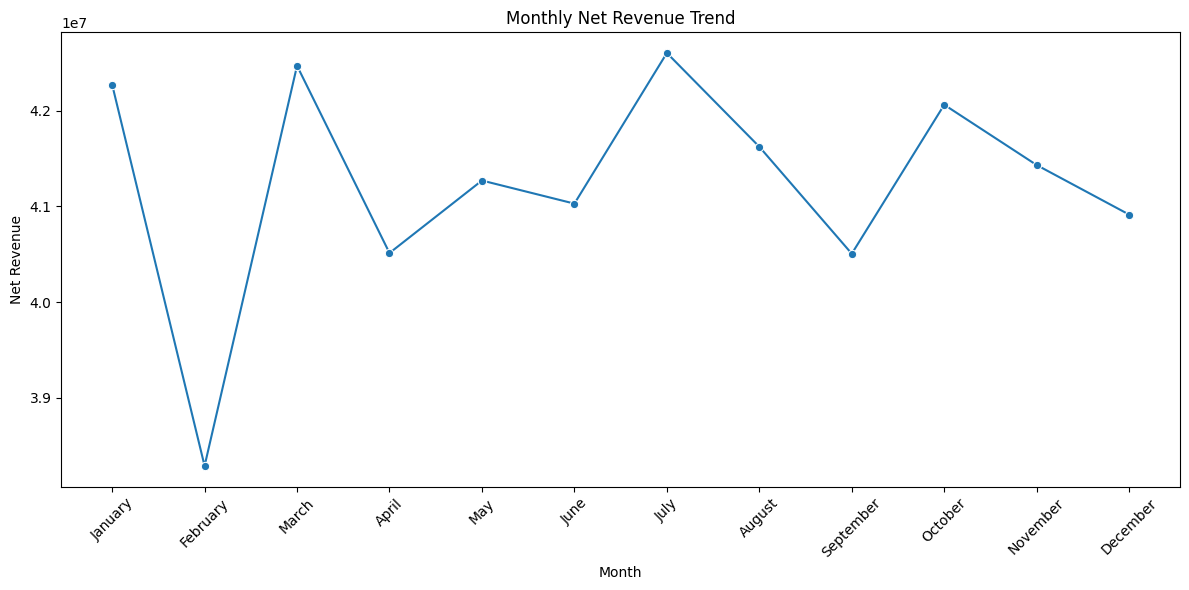

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_analysis,
    x='month',
    y='net_revenue',
    marker='o'
)

plt.title('Monthly Net Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Net Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

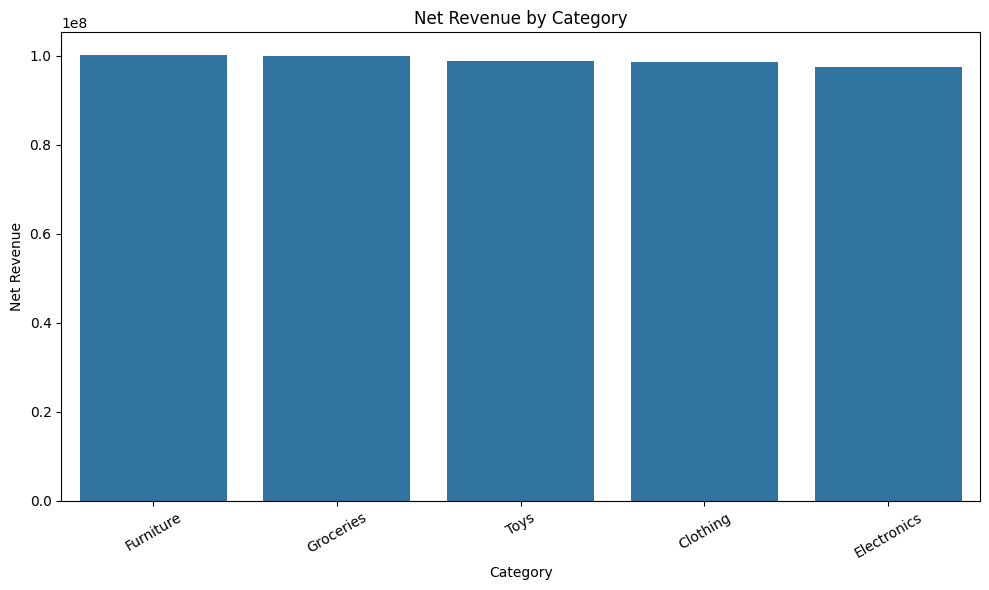

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis,
    x='category',
    y='net_revenue'
)

plt.title('Net Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Net Revenue')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

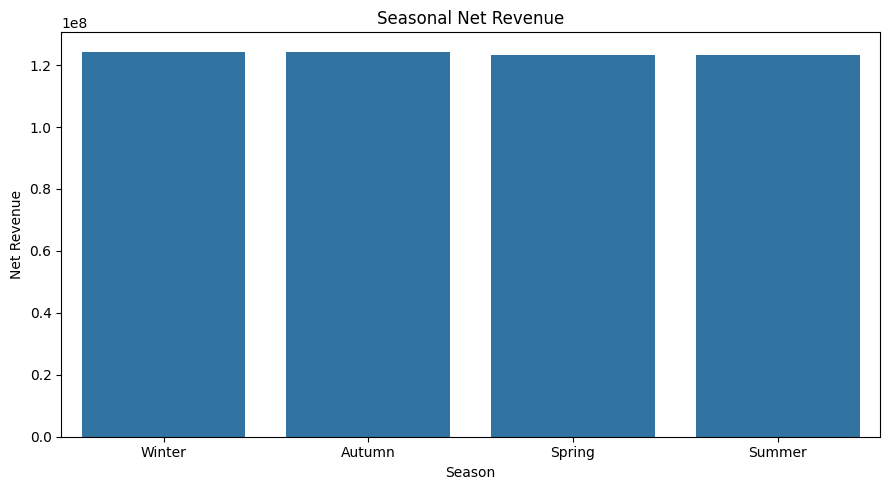

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=seasonal_analysis,
    x='seasonality',
    y='net_revenue'
)

plt.title('Seasonal Net Revenue')
plt.xlabel('Season')
plt.ylabel('Net Revenue')
plt.tight_layout()
plt.show()

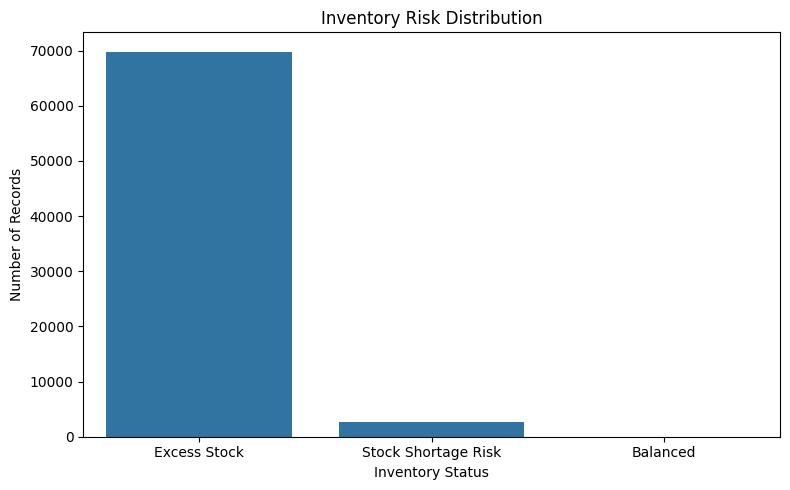

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=valid_df,
    x='inventory_status'
)

plt.title('Inventory Risk Distribution')
plt.xlabel('Inventory Status')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

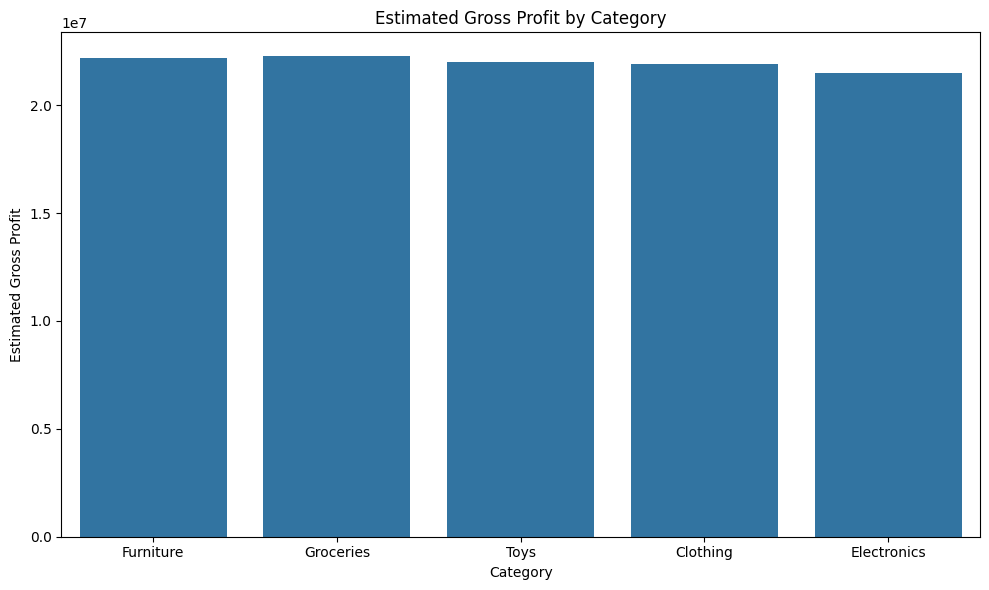

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis,
    x='category',
    y='estimated_gross_profit'
)

plt.title('Estimated Gross Profit by Category')
plt.xlabel('Category')
plt.ylabel('Estimated Gross Profit')
plt.tight_layout()
plt.show()

In [ ]:
print("RETAIL BUSINESS PERFORMANCE ANALYSIS")
print("------------------------------------")

print("Total Records:", len(df))
print("Total Stores:", df['store_id'].nunique())
print("Total Products:", df['product_id'].nunique())
print("Total Categories:", df['category'].nunique())

print("Total Units Sold:", df['units_sold'].sum())

print("Total Net Revenue:",
      round(df['net_revenue'].sum(), 2))

print("Total Estimated Gross Profit:",
      round(df['estimated_gross_profit'].sum(), 2))

print("Average Discount:",
      round(df['discount'].mean(), 2), "%")

RETAIL BUSINESS PERFORMANCE ANALYSIS
------------------------------------
Total Records: 73100
Total Stores: 5
Total Products: 20
Total Categories: 5
Total Units Sold: 9975582
Total Net Revenue: 494971374.95
Total Estimated Gross Profit: 109811155.51
Average Discount: 10.01 %


In [ ]:
df.to_csv('retail_analysis_cleaned.csv', index=False)

from google.colab import files
files.download('retail_analysis_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>